# 07 · Beignet and Sopaipilla: what you own, what Meta owes, and what the yield says

**The question:** Beignet (Hyperion, Louisiana) and Sopaipilla (El Paso, Texas) are sold as "Meta risk" and rated one notch below Meta. What is a bondholder actually entitled to? What do these deals do for Meta? And how much extra yield does the market demand for the difference between owning Meta's bonds and owning these?

**Short answer** (TRACE, Nov 10, 2026; Meta's Q3 10-Q):
1. **You own notes of a vehicle tied to the data center's owner, not a claim on Meta.** You're repaid by Meta's rent, or, if Meta leaves, by the campus plus a guarantee that is paid to the joint venture, conditional, and shrinking (§1).
2. **These are ~15-year bonds paying ~250–265bp over Treasuries,** once their principal repayments are modelled (§2).
3. **The structure costs ~110–125bp over Meta's own bonds, and that premium has narrowed since issue (~149bp)** (§3, `07_spv_premium.png`). Beignet's slide is Meta-wide widening plus interest rates.
4. **For Meta it's a cheap option:** ~$0.5B a year of extra coupon buys ~$40B off its balance sheet and the right to walk every 4 years. Renewed every time, the rent would be ~$92B, more than all of Meta's reported debt (§4, `07_meta_exposure.png`).
5. **If the premium were all default risk, it would imply absurd odds** (~35% over the bonds' life), so most of it pays for illiquidity, index exclusion and complexity (§5).
6. **Compared with Meta's own bonds, the SPV is worse if Meta is healthy but walks away, and better if Meta is sick** (§6, `07_spv_vs_meta_scenarios.png`). The buyer is paid ~110–125bp to be short Meta's option to walk.

**How this notebook gets there:**

| § | Question | Chart / table |
|---|---|---|
| 1 | What does a bondholder actually own? | (diagram, tables) |
| 2 | What do these bonds really yield, once you account for principal being repaid early? | (tables) |
| 3 | How much extra does the structure cost versus Meta's own bonds? | `07_spv_premium.png` |
| 4 | What do the deals do for Meta, and what does Meta pay for them? | `07_meta_exposure.png` |
| 5 | What would the premium imply if it were all default risk? | (table) |
| 6 | When does the SPV lose while Meta is fine, and when is it the better bond? | `07_spv_vs_meta_scenarios.png` |

**Sources:**
- Meta's Q3 2026 10-Q (primary).
- Meta's own term sheets (primary).
- FINRA TRACE prices.
- Press and newsletter accounts of the S&P/Fitch reports. The agency reports themselves are paywalled.

Hand-entered figures live in `data/meta_spv_exposure.csv`, `data/meta_spv_facts.csv`, and `data/meta_curve_2025-10-30.csv`, each with a source.

**Outputs:** the three `charts/07_*.png`.

## 1 · The structure, in plain terms

```
            rent (4-yr leases, renewable to 20 yrs)
   Meta  ───────────────────────────────────────────►  JV  (owns the data center campus)
    │  residual value guarantee (to the JV)           ▲  80% Blue Owl (LA) / BlackRock GIP+HPS (TX)
    │  cost-overrun backstop (>105% of budget, LA)    │  20% Meta
    │                                                 │
    └── 20% equity, and took cash out at formation    │ funds construction
                                                      │
                     Beignet / Sopaipilla Investor LLC (issuer)  ◄── bondholders
```

**What a bondholder owns:** senior secured notes of an *issuer vehicle* tied to the JV. The bonds aren't issued or guaranteed by Meta. The money to repay them comes from Meta's rent, and if Meta leaves, from the campus's value plus Meta's residual value guarantee. S&P rates them one notch *below* Meta (A+ vs. AA-), citing "the absence of a direct asset pledge." Fitch rates Sopaipilla AA-, equal to Meta.

**The key terms, and where they come from:**

| Term | Beignet (Louisiana) | Sopaipilla (Texas) | Source |
|---|---|---|---|
| Bonds | $27.3B, 6.581%, May 2049, amortizing, quarterly | $12.547B, 7.534%, Nov 2048, amortizing | term sheets via press; `bonds.csv` |
| Development cost | ~$27B | ~$14B | Meta 10-Q |
| Equity | Blue Owl 80% (~$7B cash), Meta 20% | BlackRock GIP/HPS 80%, Meta 20% | Meta 10-Q; press |
| Cash Meta took out at formation | ~$3B | $1.04B (after contributing $2.26B of assets) | press; Meta 10-Q |
| Lease starts | 2029 | 2028 | Meta 10-Q |
| Lease term | 4-year initial term, renewals up to 20 years | same | Meta 10-Q |
| Residual value guarantee (RVG) | max ~$28.1B, declining, first 16 years | max ~$13.4B (= $41.5B − $28.1B), declining | Meta 10-Q |
| Last 4 years | termination fee ≈ outstanding bonds | (presumably same) | IFR |
| Rating | S&P A+ | S&P A+, Fitch AA- | press |

**The 4-year lease is the whole trick.** Meta only has to commit to 4 years at a time. Under US accounting, if renewal isn't "reasonably certain," only those 4 years count, so Meta books no debt and only a small lease commitment. And because Meta doesn't control "remarketing" decisions (re-letting or selling the campus), it isn't the venture's "primary beneficiary," so the venture isn't consolidated either (10-Q, Note 5).

**The bondholder's position in each scenario:**

| What happens | Who pays the bonds | What could go wrong |
|---|---|---|
| Meta renews every time through ~2049 | Meta's rent (S&P: 1.12x debt-service coverage once operating) | Nothing beyond Meta's own credit |
| Meta walks at a renewal date in years 4–16 | Campus sale or re-letting, plus the RVG for any shortfall below a declining threshold | The RVG pays the **JV**, not the noteholders. It only pays "if certain other conditions are met" (undisclosed). Its decline schedule is undisclosed. |
| Meta walks in years 17–20 | Termination fee ≈ outstanding bonds (IFR) | Meta's credit |
| Fire, storm, or construction delay > 18 months | Insurance (Sopaipilla: ~$450M property cap vs. a ~$14B campus). Meta may terminate without penalty (per S&P via press). | **Uninsured loss, and possibly no lease.** This is the one scenario where Meta can leave without the RVG. |
| Meta itself defaults | Nobody. Recovery is whatever the campus is worth | Same as any Meta bond, but you own a specialised building instead of a claim on Meta |

The rating rests on the RVG making bondholders whole if Meta leaves. Its threshold was sized to roughly match the bonds: ~$28.1B vs. $27.3B (Beignet), and ~$13.4B vs. $12.5B (Sopaipilla). The fine print is what the market is pricing.

**Next:** 02 and 03 treated these as 22-year bullet bonds. They aren't, which changes the yield. §2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from common import INK, INK2, MUTED, AXIS, GRID, SURFACE, BOND, RAMP, EQUITY, source_note, treasury_yield

CHARTS = Path('charts')
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
spreads = pd.read_csv('data/spreads.csv', parse_dates=['as_of'])
issuers = pd.read_csv('issuers.csv').set_index('issuer')
exposure = pd.read_csv('data/meta_spv_exposure.csv', comment='#', index_col='item')
facts = pd.read_csv('data/meta_spv_facts.csv').set_index(['bond_id', 'fact']).value
meta_oct25 = pd.read_csv('data/meta_curve_2025-10-30.csv', comment='#', parse_dates=['as_of', 'maturity'])
SPV = {'BEIGNET_6.581_2049': 'Beignet', 'SOPAIPILLA_2048': 'Sopaipilla'}
FREQ = {'BEIGNET_6.581_2049': 4, 'SOPAIPILLA_2048': 2}   # Beignet quarterly (bonds.csv); Sopaipilla not confirmed, assume semiannual
AS_OF = spreads[spreads.kind == 'trade'].as_of.max()
pd.options.display.float_format = '{:,.2f}'.format

## 2 · What do these bonds really yield, once you account for principal being repaid early?

So far (02, 03) we treated both bonds as **bullets**: everything repaid at final maturity, ~22 years out. They actually **amortize**: principal is repaid along the way once rent starts. That matters twice:
1. **The yield.** At a discount price (90.5), getting principal back sooner is worth more, so the true yield is *higher* than the bullet yield.
2. **The benchmark.** The right Treasury to compare with matches the bond's **weighted average life (WAL)**, the average time until each dollar of principal comes back, not its final maturity.

**Amortization assumption** (the schedules aren't public): interest-only until the lease starts (Jan 2029 Louisiana, Jan 2028 Texas, per Meta's 10-Q), then level payments, like a mortgage, until maturity. The rent is roughly level, and S&P's 1.12x coverage figure implies the debt is sized to the rent. §2b tests a year earlier or later, and straight-line principal instead.

$$\text{WAL} = \frac{\sum_i t_i \times \text{principal}_i}{\sum_i \text{principal}_i}$$

Yields are converted to the semiannual convention Treasuries use, so a quarterly-pay bond's yield is comparable. Quoted prices are *clean* (they exclude interest accrued since the last coupon), so accrued interest is added before solving.

In [2]:
def schedule(coupon, maturity, amort_start, freq, level=True):
    """Cash flows per 100 face: interest-only until amort_start, then level (or straight-line) principal to maturity."""
    step, dates, d = 12 // freq, [], maturity
    while d > pd.Timestamp('2025-06-01'):
        dates.append(d); d -= pd.DateOffset(months=step)
    dates = sorted(dates)
    r, n = coupon / 100 / freq, sum(d > amort_start for d in dates)
    pmt = 100 * r / (1 - (1 + r) ** -n) if n else 0.0   # n = 0 means a bullet
    bal, rows = 100.0, []
    for d in dates:
        interest = bal * r
        principal = 0.0 if d <= amort_start else (pmt - interest if level else 100 / n)
        if d == dates[-1]: principal = bal
        rows.append((d, interest, principal)); bal -= principal
    return pd.DataFrame(rows, columns=['date', 'interest', 'principal']).set_index('date')

def analyse(sched, price, as_of, freq):
    s = sched[sched.index > as_of]
    t = ((s.index - as_of).days / 365.25).values
    cf, prin = (s.interest + s.principal).values, s.principal.values
    nxt = s.index[0]; prev = nxt - pd.DateOffset(months=12 // freq)
    price = price + s.interest.iloc[0] * (as_of - prev).days / (nxt - prev).days   # quotes are clean: add accrued interest
    pv = lambda y: (cf / (1 + y / freq) ** (t * freq)).sum()
    lo, hi = -0.5, 1.0
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if pv(mid) > price else (lo, mid)
    y_sa = 2 * ((1 + mid / freq) ** (freq / 2) - 1) * 100          # semiannual-equivalent, % (Treasury convention)
    wal = (t * prin).sum() / prin.sum()
    return {'yield': y_sa, 'WAL': wal, 'tsy@WAL': treasury_yield(as_of, wal), 'spread@WAL': (y_sa - treasury_yield(as_of, wal)) * 100}

# checks: a par bond yields its coupon; a bullet's WAL is its maturity
_b = schedule(6.0, pd.Timestamp('2035-06-01'), pd.Timestamp('2035-06-01'), 2)
assert abs(analyse(_b, 100, pd.Timestamp('2025-06-01'), 2)['yield'] - 6.0) < 0.01   # day-count rounding only
assert abs(analyse(_b, 100, pd.Timestamp('2025-08-15'), 2)['yield'] - 6.0) < 0.02   # also between coupon dates
assert abs(analyse(_b, 100, pd.Timestamp('2025-06-01'), 2)['WAL'] - 10.0) < 0.01

AMORT_START = {b: pd.Timestamp(f"{int(facts[(b, 'lease_commencement_year')])}-01-01") for b in SPV}
scheds = {b: schedule(bonds.loc[b, 'coupon'], bonds.loc[b, 'maturity'], AMORT_START[b], FREQ[b]) for b in SPV}

rows = []
for b, name in SPV.items():
    q = spreads[spreads.bond_id == b]
    for _, r in q.iterrows():
        price = r.price if pd.notna(r.price) else 100.0      # issue rows are at par
        a = analyse(scheds[b], price, r.as_of, FREQ[b])
        rows.append({'bond': name, 'as_of': r.as_of.date(), 'kind': r.kind, 'price': price, 'bullet yield (02)': r['yield'],
                     'bullet spread (02)': r.g_spread, **a})
amort = pd.DataFrame(rows).sort_values(['bond', 'as_of'])
amort

,bond,as_of,kind,price,bullet yield (02),bullet spread (02),yield,WAL,tsy@WAL,spread@WAL
0,Beignet,2025-10-16,issue,100.00,6.58,201.38,6.64,15.71,4.32,231.95
1,Beignet,2026-09-28,trade,91.00,7.55,196.07,7.73,14.76,5.41,231.79
2,Beignet,2026-10-07,trade,91.00,7.41,170.60,7.73,14.74,5.48,224.70
3,Beignet,2026-10-19,trade,92.00,7.31,179.15,7.60,14.70,5.33,227.38
4,Beignet,2026-10-23,trade,90.52,7.45,209.48,7.80,14.69,5.17,262.34
5,Beignet,2026-11-10,trade,92.21,7.29,200.70,7.58,14.64,5.07,250.83
6,Sopaipilla,2026-07-27,issue,100.00,7.53,239.10,7.53,14.71,4.89,264.59
8,Sopaipilla,2026-07-28,trade,103.00,7.31,220.47,7.18,14.70,4.85,233.52
7,Sopaipilla,2026-10-23,trade,98.38,7.69,232.55,7.73,14.47,5.17,256.65
9,Sopaipilla,2026-11-10,trade,98.65,7.66,237.67,7.70,14.42,5.06,263.85


**What this shows:**
- **Weighted average life is 14.7 years (Beignet) and 14.5 (Sopaipilla),** not ~22. These are really ~15-year bonds.
- **Spread at average life: ~251bp (Beignet) and ~264bp (Sopaipilla) on Nov 10,** against ~205–240bp under the bullet shortcut in 02. A shorter (cheaper) Treasury benchmark and faster principal return both widen the true spread.
- **Check:** the model puts Beignet's issue spread at 232bp, against the press-reported "T+225". That's a reasonable test of the amortization assumption.

### 2b · How much does the amortization assumption matter?

In [3]:
sens = []
for b, name in SPV.items():
    last = spreads[(spreads.bond_id == b) & (spreads.kind == 'trade')].sort_values('as_of').iloc[-1]
    for lbl, start, level in [('base: level from lease start', AMORT_START[b], True),
                              ('start 1 yr earlier', AMORT_START[b] - pd.DateOffset(years=1), True),
                              ('start 1 yr later', AMORT_START[b] + pd.DateOffset(years=1), True),
                              ('straight-line principal', AMORT_START[b], False),
                              ('bullet (as in 02)', bonds.loc[b, 'maturity'], True)]:
        a = analyse(schedule(bonds.loc[b, 'coupon'], bonds.loc[b, 'maturity'], start, FREQ[b], level), last.price, last.as_of, FREQ[b])
        sens.append({'bond': name, 'assumption': lbl, **a})
pd.DataFrame(sens).set_index(['bond', 'assumption'])

yield   WAL  tsy@WAL  spread@WAL
bond       assumption                                                    
Beignet    base: level from lease start   7.58 14.64     5.07      250.83
           start 1 yr earlier             7.60 14.36     5.06      253.82
           start 1 yr later               7.56 14.94     5.08      247.89
           straight-line principal        7.70 12.42     4.98      271.91
           bullet (as in 02)              7.35 22.55     5.28      207.08
Sopaipilla base: level from lease start   7.70 14.42     5.06      263.85
           start 1 yr earlier             7.70 14.16     5.05      265.19
           start 1 yr later               7.70 14.68     5.07      262.49
           straight-line principal        7.72 11.80     4.95      277.10
           bullet (as in 02)              7.66 22.06     5.28      237.77

**What this shows:** starting amortization a year earlier or later barely moves the spread. Straight-line principal makes it *wider*. Treating the bonds as bullets (02's shortcut) is the outlier.

**Next:** ~250–265bp over Treasuries, but how much of that is Meta, and how much is the structure? §3 compares with Meta's own bonds of the same life.

## 3 · How much extra does the structure cost versus Meta's own bonds?

The cleanest way to price "the structure" is to compare each SPV bond with **Meta's own unsecured bonds at the same average life**. Same ultimate payer, same industry, same news. The gap is what investors charge for owning the structure instead of Meta's promise.

- **Then:** Meta sold $30B of its own bonds on Oct 30, 2025, two weeks after Beignet. Its term-sheet yields give Meta's curve at Beignet's issue.
- **Now:** Nov 10, 2026 TRACE trades for Meta's 2031/2036/2056/2064 bonds and both SPVs.

Meta's curve at the SPV's WAL is interpolated linearly between Meta's bonds. All spreads are computed the same way: yield minus the interpolated Treasury on the same day.

In [4]:
def meta_curve_now():
    m = spreads[(spreads.issuer == 'Meta') & (spreads.kind == 'trade') & (spreads.as_of == AS_OF)]
    return m.years.values, m.g_spread.values

def meta_curve_oct25():
    yrs = ((meta_oct25.maturity - meta_oct25.as_of).dt.days / 365.25).values
    g = [(y - treasury_yield(d, t)) * 100 for y, d, t in zip(meta_oct25.yield_pct, meta_oct25.as_of, yrs)]
    return yrs, np.array(g)

curves = {'Oct 2025': meta_curve_oct25(), f'{AS_OF:%b %-d, %Y}': meta_curve_now()}
prem = []
for b, name in SPV.items():
    for when, kind, date in [('Oct 2025', 'issue', None), (f'{AS_OF:%b %-d, %Y}', 'trade', AS_OF)]:
        sel = amort[(amort.bond == name) & (amort.kind == kind)]
        if date is not None: sel = sel[sel.as_of == date.date()]
        if sel.empty or (kind == 'issue' and name == 'Sopaipilla'): continue   # no Meta curve on Sopaipilla's issue date
        r = sel.iloc[-1]
        x, g = curves[when]
        meta_at = float(np.interp(r.WAL, x, g))
        prem.append({'bond': name, 'when': when, 'as_of': r.as_of, 'WAL': r.WAL, 'SPV spread': r['spread@WAL'],
                     'Meta at same life': meta_at, 'structure premium': r['spread@WAL'] - meta_at})
prem = pd.DataFrame(prem)
prem

,bond,when,as_of,WAL,SPV spread,Meta at same life,structure premium
0,Beignet,Oct 2025,2025-10-16,15.71,231.95,82.72,149.22
1,Beignet,"Nov 10, 2026",2026-11-10,14.64,250.83,141.02,109.80
2,Sopaipilla,"Nov 10, 2026",2026-11-10,14.42,263.85,140.15,123.70


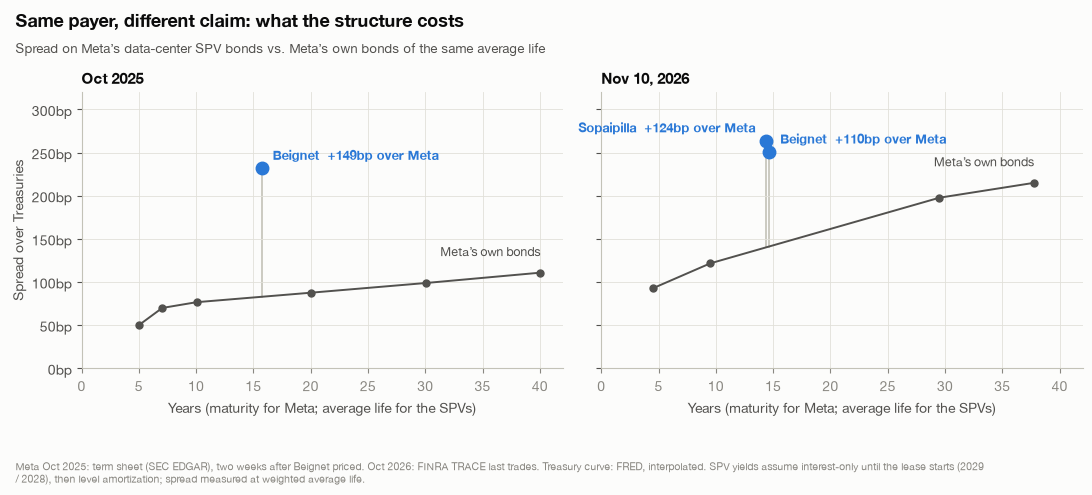

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (when, (x, g)) in zip(axes, curves.items()):
    o = np.argsort(x)
    ax.plot(x[o], g[o], color=INK2, lw=1.4, marker='o', ms=5, zorder=2)
    ax.annotate('Meta’s own bonds', (x[o][-1], g[o][-1]), xytext=(0, 10), textcoords='offset points', ha='right',
                va='bottom', fontsize=9, color=INK2)
    for bond, wal, spv, meta_at, p in prem.loc[prem.when == when, ['bond', 'WAL', 'SPV spread', 'Meta at same life', 'structure premium']].itertuples(index=False):
        ax.plot([wal, wal], [meta_at, spv], color=AXIS, lw=1.2, zorder=1)
        ax.plot(wal, spv, 'o', ms=9, color=BOND, zorder=3)
        dx = 8 if bond == 'Beignet' else -8
        ax.annotate(f'{bond}  +{p:.0f}bp over Meta', (wal, spv), xytext=(dx, 4), textcoords='offset points',
                    ha='left' if dx > 0 else 'right', va='bottom', fontsize=9, color=BOND, fontweight='bold')
    ax.set_title(when, fontsize=11)
    ax.set_xlim(0, 42); ax.set_ylim(0, 320)
    ax.set_xlabel('Years (maturity for Meta; average life for the SPVs)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}bp'))
axes[0].set_ylabel('Spread over Treasuries')
fig.suptitle('Same payer, different claim: what the structure costs', x=0.01, ha='left', fontweight='bold', fontsize=13)
fig.text(0.01, 0.885, 'Spread on Meta’s data-center SPV bonds vs. Meta’s own bonds of the same average life', fontsize=9.5, color=INK2)
source_note(fig, 'Meta Oct 2025: term sheet (SEC EDGAR), two weeks after Beignet priced. Oct 2026: FINRA TRACE last trades. Treasury curve: FRED, interpolated.\n'
                 'SPV yields assume interest-only until the lease starts (2029 / 2028), then level amortization; spread measured at weighted average life.')
fig.subplots_adjust(left=0.07, right=0.98, bottom=0.2, top=0.8, wspace=0.08)
fig.savefig(CHARTS / '07_spv_premium.png', dpi=200)
plt.show()

**What this shows** (`charts/07_spv_premium.png`, above):

**The structure costs ~110–125bp over Meta's own bonds, and that premium has narrowed since issue.** At issue, Beignet paid ~149bp more than a Meta bond of the same life. Today Beignet pays ~110bp more and Sopaipilla ~124bp more. Over the year, Meta's *own* 15-year spread widened ~58bp (83 → 141bp), while Beignet's widened only ~19bp. **So Beignet's slide is Meta-wide widening plus interest rates, not the market souring on the structure.** Notebook 05 says the same thing from prices: all of Beignet's ~8-point fall is rates.

**The two deals now price the same.** Sopaipilla came ~40bp wide of where Beignet was trading in July (a new-deal concession on a nervous day), jumped to 103 the next morning, and has since drifted back to its issue spread. Beignet and Sopaipilla are now within ~15bp of each other at the same average life. The market treats them as nearly one structure.

**Next:** someone pays that premium, ultimately Meta, through the rent. What does Meta get for it? §4.

## 4 · What do the deals do for Meta, and what does Meta pay for them?

### 4a · What's on the balance sheet vs. what Meta is on the hook for

Meta reports $84B of its own debt. The two SPVs carry another ~$40B that isn't on Meta's balance sheet. What Meta *does* disclose is its "maximum exposure to loss" (10-Q Note 5): equity, the first 4 years of rent, future funding, and the maximum RVG. We add one estimate: **20 years of rent**, the economic commitment if Meta renews every time. It's estimated as 5× the disclosed 4-year commitment, assuming flat rent:
- Louisiana's 4-year commitment was $12.3B at Dec 2025, before Texas existed, which is ~$3.1B a year.
- Texas is the Sep 2026 total minus that figure: ~$1.5B a year.

In [6]:
spv_debt = bonds.loc[list(SPV), 'issue_size_usd_bn']
la_rent_4y = exposure.loc['Lease commitments', '2025-12-31']
tx_rent_4y = exposure.loc['Lease commitments', '2026-09-30'] - la_rent_4y
rent = pd.Series({'BEIGNET_6.581_2049': la_rent_4y / 4, 'SOPAIPILLA_2048': tx_rent_4y / 4})

# debt service in the first full amortizing year, scaled to the bond size
ds = {b: (s.loc[str(AMORT_START[b].year + 1)].sum(axis=1).sum()) / 100 * spv_debt[b] for b, s in scheds.items()}
cov = pd.DataFrame({'bonds ($bn)': spv_debt, 'est. annual rent ($bn)': rent, 'modelled debt service ($bn/yr)': pd.Series(ds),
                    'RVG max ($bn)': pd.Series({'BEIGNET_6.581_2049': exposure.loc['Maximum residual value guarantees', '2025-12-31'],
                                                'SOPAIPILLA_2048': exposure.loc['Maximum residual value guarantees', '2026-09-30']
                                                                   - exposure.loc['Maximum residual value guarantees', '2025-12-31']})})
cov['rent ÷ debt service'] = cov['est. annual rent ($bn)'] / cov['modelled debt service ($bn/yr)']
cov['RVG ÷ bonds'] = cov['RVG max ($bn)'] / cov['bonds ($bn)']
cov.index = cov.index.map(SPV)
cov

,bonds ($bn),est. annual rent ($bn),modelled debt service ($bn/yr),RVG max ($bn),rent ÷ debt service,RVG ÷ bonds
Beignet,27.29,3.08,2.44,28.09,1.26,1.03
Sopaipilla,12.55,1.54,1.20,13.40,1.29,1.07


**What this shows** (coverage table):

**The guarantee is sized to the bonds.** Meta's maximum RVG is 1.03× Beignet's bonds and 1.07× Sopaipilla's, and estimated rent covers modelled debt service ~1.26–1.29×. (S&P's 1.12× for Beignet implies either lower net rent or a front-loaded repayment schedule.) On paper, a bondholder is repaid either by Meta's rent or by Meta's guarantee. The premium is the market's price on the gaps in that "either":
- The RVG is paid to the JV, not to the noteholders.
- It pays only if undisclosed "other conditions" are met.
- It declines over time.
- After a catastrophic delay of more than 18 months, Meta may be able to walk away with no guarantee owed, and the campus is insured for a small fraction of its value.

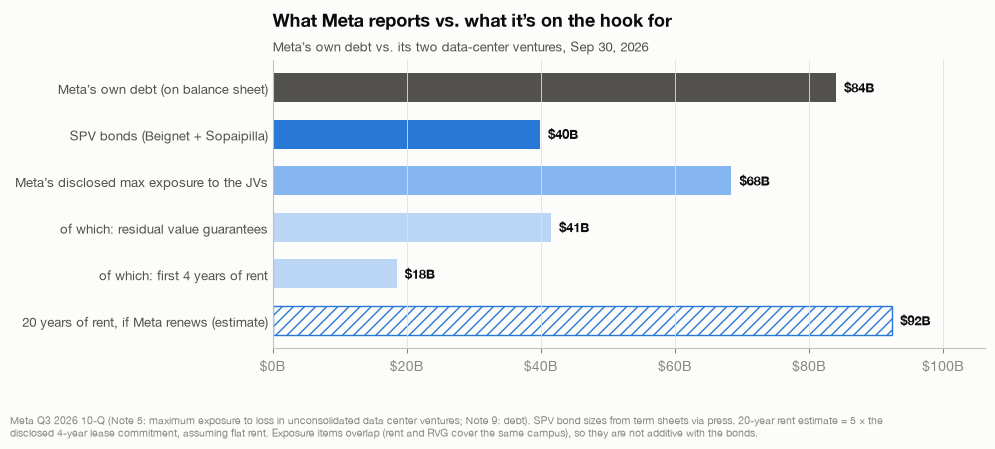

In [7]:
bars = [
    ('Meta’s own debt (on balance sheet)', issuers.loc['Meta', 'debt_face_bn'], 'on'),
    ('SPV bonds (Beignet + Sopaipilla)', spv_debt.sum(), 'off'),
    ('Meta’s disclosed max exposure to the JVs', exposure['2026-09-30'].sum(), 'disc'),
    ('   of which: residual value guarantees', exposure.loc['Maximum residual value guarantees', '2026-09-30'], 'disc_sub'),
    ('   of which: first 4 years of rent', exposure.loc['Lease commitments', '2026-09-30'], 'disc_sub'),
    ('20 years of rent, if Meta renews (estimate)', 5 * exposure.loc['Lease commitments', '2026-09-30'], 'est'),
]
style = {'on': dict(color=INK2), 'off': dict(color=BOND), 'disc': dict(color=RAMP[0]), 'disc_sub': dict(color=RAMP[0], alpha=0.55),
         'est': dict(facecolor=SURFACE, edgecolor=BOND, hatch='///', lw=1)}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (lbl, v, k) in enumerate(bars):
    ax.barh(i, v, height=0.62, **style[k])
    ax.annotate(f'${v:,.0f}B', (v, i), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=INK, fontweight='bold')
ax.set_yticks(range(len(bars)), [b[0] for b in bars], fontsize=9.5)
ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}B'))
ax.set_xlim(0, max(b[1] for b in bars) * 1.15)
ax.set_title('What Meta reports vs. what it’s on the hook for', pad=24)
ax.text(0, 1.03, 'Meta’s own debt vs. its two data-center ventures, Sep 30, 2026', transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'Meta Q3 2026 10-Q (Note 5: maximum exposure to loss in unconsolidated data center ventures; Note 9: debt). SPV bond sizes from term sheets via press.\n'
                 '20-year rent estimate = 5 × the disclosed 4-year lease commitment, assuming flat rent. Exposure items overlap (rent and RVG cover the same campus), so they are not additive with the bonds.')
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(CHARTS / '07_meta_exposure.png', dpi=200)
plt.show()

**What this shows** (`charts/07_meta_exposure.png`, above):
- Meta reports **$84B** of its own debt.
- The SPV bonds add **$40B** that isn't on its balance sheet.
- Meta's disclosed maximum exposure is **$68B**, mostly the guarantees ($41B) and the first 4 years of rent ($18B).
- If Meta renews every time, 20 years of rent comes to **~$92B**, more than all its reported debt.
- These items overlap: rent and guarantee cover the same campus. So don't add them to the bonds.

### 4b · What Meta pays for the privilege

Meta's rent has to cover the SPV's coupon, so the extra coupon is, roughly, extra financing cost Meta bears versus borrowing in its own name. (On top of that comes the equity return to Blue Owl or BlackRock, which isn't disclosed.)

What Meta gets for it:
1. **~$40B of borrowing that isn't on its balance sheet,** an addition of nearly half to its $84B of reported debt. (S&P says consolidating Hyperion wouldn't change Meta's rating. The benefit is in the reported numbers, not the rating.)
2. **A walk-away option every 4 years.** If AI demand or chip designs move on, Meta can leave. Its worst case is the RVG shortfall, not 20 years of rent.
3. **Cash up front:** ~$3B (Louisiana) and $1.04B (Texas) distributed to Meta at formation.

Below, the coupon-cost estimate uses the structure premium from §3 on each bond's outstanding size.

In [8]:
now = prem[prem.when != 'Oct 2025'].set_index('bond')
cost = pd.DataFrame({'bonds ($bn)': spv_debt.rename(SPV), 'structure premium now (bp)': now['structure premium']})
cost['extra coupon cost ($bn/yr)'] = cost['bonds ($bn)'] * cost['structure premium now (bp)'] / 1e4
cost

,bonds ($bn),structure premium now (bp),extra coupon cost ($bn/yr)
Beignet,27.29,109.80,0.30
Sopaipilla,12.55,123.70,0.16


**What this shows:**

**For Meta, it's a cheap option, and a big off-balance-sheet number.** Meta pays roughly **$0.5B a year** in extra coupon (at today's premium) for:
- ~$40B of borrowing that isn't on its balance sheet, nearly half again its $84B of reported debt;
- the right to walk away every four years;
- ~$4B of cash taken out at formation.

If Meta renews every time, it's committed to roughly **$92B of rent**, more than its entire reported debt. Its disclosed "maximum exposure" is $68B. The quiet part: the rating agencies say none of this changes Meta's AA-, and the bond market agrees, charging Meta's own bonds nothing for it (05). The cost lands on the SPV bondholders' spread, and they're paid ~110–125bp a year to carry it.

**Next:** bondholders are paid ~110–125bp a year for the gaps in the structure. Is that pay for default risk? §5 tests the extreme case where all of it is.

## 5 · What the premium implies, if it were all default risk

Using the credit triangle from 03 on the **premium alone**: a bondholder loses money only if Meta leaves *and* the guarantee doesn't make them whole (the conditions fail, the RVG shortfall goes to the JV and gets stuck there, or there's an uninsured catastrophe). If that happens, the loss is the shortfall on a specialised campus. Say 40% (the 60% recovery in `bonds.csv`).

$$\text{annual chance of "Meta leaves and the guarantee fails"} \approx \frac{\text{premium}}{1 - R}$$

Like everything in 03, this is an upper bound: part of the premium is pay for illiquidity (144A, concentrated holders; PIMCO took ~$18B of Beignet) and for complexity.

In [9]:
R = bonds.loc[list(SPV), 'assumed_recovery'].rename(SPV)
imp = now[['WAL', 'structure premium']].copy()
imp['R'] = R
imp['annual odds'] = imp['structure premium'] / 1e4 / (1 - imp.R)
imp['odds over WAL'] = 1 - (1 - imp['annual odds']) ** imp.WAL
imp.style.format({'WAL': '{:.1f}', 'structure premium': '{:.0f}bp', 'R': '{:.0%}', 'annual odds': '{:.1%}', 'odds over WAL': '{:.0%}'})

,WAL,structure premium,R,annual odds,odds over WAL
bond,,,,,
Beignet,14.6,110bp,60%,2.7%,33%
Sopaipilla,14.4,124bp,60%,3.1%,36%


**What this shows:**

**If the premium were all default risk, it would be absurd.** At 60% recovery, a ~110–125bp premium implies a ~2.7–3.1% *annual* chance that Meta walks *and* the guarantee fails, about 35% over the bonds' life. Nobody believes that. So most of the premium pays for things other than default:
- **Illiquidity.** These are 144A notes with a handful of holders; PIMCO took ~$18B of Beignet's $27.3B.
- **Index exclusion.** 144A notes without registration rights are left out of the main investment-grade indices, so index money can't buy them. Whether these notes have registration rights is unverified.
- **Complexity and amortization.**
- **Headline risk** attached to the AI capex boom.

For an investor who reads the documents and is comfortable with the gaps, that's the pitch: Meta-adjacent risk at about twice Meta's spread.

**Next:** averages hide the scenarios a buyer actually faces. §6 walks through when the SPV loses while Meta is fine, and when it beats Meta's own bonds.

## 6 · Why own the SPV instead of Meta? The scenarios where they diverge

§5 asked what the premium implies *on average*. This section asks the question a buyer actually faces: **in which specific worlds does the SPV bond lose money while Meta's own bonds are fine, and in which worlds is the SPV bond the better thing to own?**

Two kinds of world matter:

| World | Meta's own bonds | SPV bonds |
|---|---|---|
| **A · Meta is fine, but it leaves the campus** (walks at a renewal, or after a catastrophe) | Paid in full | Paid in full *only if* the guarantee works; otherwise they own a building |
| **B · Meta itself gets into trouble** | Unsecured claim, recover ~40% (`bonds.csv`) | Secured on a campus Meta probably still needs, plus a claim on Meta for any shortfall |

In world A, the SPV holder's cushion is the premium itself: ~110–125bp a year of extra coupon. So the test is whether the loss in a bad scenario is bigger than the extra coupon earned up to that point.

**Assumptions, all per $100 of original face:**
- **Balance outstanding** comes from the modelled amortization schedule (§2).
- **Meta can walk** at each 4-year renewal: 2033, 2037, 2041, 2045 for Beignet; a year earlier for Sopaipilla.
- **Campus value if Meta leaves** is 50% or 25% of development cost. Nobody knows what a 2-gigawatt campus in rural Louisiana sells for without its tenant. It's a specialised building whose GPUs belong to Meta, not the JV. These are scenario values, not estimates.
- **"Guarantee fails"** means the RVG pays the bondholders nothing: the conditions aren't met, or the money is stuck at the JV.
- **"Guarantee works, but it shrinks"** assumes a hypothetical decline: the threshold falls in a straight line from its maximum to zero over the 16 years after the lease starts. The real schedule isn't public. In this case the bondholder gets the higher of the threshold and the campus value.
- **Catastrophe before the lease starts** (the >18-month delay clause): Meta owes no rent and no guarantee. The bondholder gets insurance (~3.2% of project value, the Sopaipilla figure, assumed for both) plus salvage of 10% of cost.
- **Extra coupon** is earned from today at the current structure premium (§3) on the outstanding balance, and isn't reinvested.

In [10]:
CAMPUS = [0.50, 0.25]          # campus value if Meta leaves, share of development cost (scenario values)
INSURANCE, SALVAGE = 0.032, 0.10   # catastrophe: insurance (Sopaipilla's ~3.2% of value) + salvage, share of cost

def paths(b):
    """Per 100 original face, at each payment date: balance outstanding, extra coupon earned since AS_OF, and losses if Meta leaves."""
    s = scheds[b]
    bal_before = (100 - s.principal.cumsum()).shift(1, fill_value=100.0)       # balance during the period ending at each date
    cost_per_100 = facts[(b, 'development_cost')] / spv_debt[b] * 100
    rvg0 = cov.loc[SPV[b], 'RVG max ($bn)'] / spv_debt[b] * 100
    yrs_into_lease = np.clip((s.index - AMORT_START[b]).days.values / 365.25, 0, None)
    threshold = rvg0 * np.clip(1 - yrs_into_lease / 16, 0, None)                   # hypothetical straight-line decline
    p = pd.DataFrame({'balance': bal_before}, index=s.index)
    p['extra coupon earned'] = (now.loc[SPV[b], 'structure premium'] / 1e4 * bal_before / FREQ[b]).where(s.index > AS_OF, 0).cumsum()
    for c in CAMPUS:
        p[f'loss: guarantee fails, campus {c:.0%}'] = (p.balance - c * cost_per_100).clip(lower=0)
    p[f'loss: guarantee shrinks, campus {CAMPUS[-1]:.0%}'] = (p.balance - np.maximum(threshold, CAMPUS[-1] * cost_per_100)).clip(lower=0)
    p['loss: catastrophe pre-lease'] = (p.balance - (INSURANCE + SALVAGE) * cost_per_100).clip(lower=0)
    return p

P = {b: paths(b) for b in SPV}

rows = []
for b, name in SPV.items():
    p, start = P[b], AMORT_START[b]
    events = [('catastrophe before lease start', start - pd.DateOffset(months=6))] + \
             [(f'Meta walks at renewal {k}', start + pd.DateOffset(years=4 * k)) for k in range(1, 5)]
    for what, d in events:
        r = p.loc[:d].iloc[-1]
        losses = r[[c for c in p if c.startswith('loss')]]
        if what.startswith('catastrophe'): losses = losses[['loss: catastrophe pre-lease']]
        else: losses = losses.drop('loss: catastrophe pre-lease')
        for scen, loss in losses.items():
            rows.append({'bond': name, 'event': what, 'year': d.year, 'scenario': scen.replace('loss: ', ''),
                         'balance': r.balance, 'extra coupon earned': r['extra coupon earned'], 'loss': loss,
                         'net vs. owning Meta': r['extra coupon earned'] - loss})
walk = pd.DataFrame(rows)
walk.pivot_table(index=['bond', 'year', 'event'], columns='scenario', values='net vs. owning Meta', sort=False).round(1)

scenario                                        catastrophe pre-lease  \
bond       year event                                                   
Beignet    2028 catastrophe before lease start                 -85.00   
           2033 Meta walks at renewal 1                           NaN   
           2037 Meta walks at renewal 2                           NaN   
           2041 Meta walks at renewal 3                           NaN   
           2045 Meta walks at renewal 4                           NaN   
Sopaipilla 2027 catastrophe before lease start                 -84.00   
           2032 Meta walks at renewal 1                           NaN   
           2036 Meta walks at renewal 2                           NaN   
           2040 Meta walks at renewal 3                           NaN   
           2044 Meta walks at renewal 4                           NaN   

scenario                                        guarantee fails, campus 50%  \
bond       year event                                                         
Beignet    2028 catastrophe before lease start                          NaN   
           2033 Meta walks at renewal 1                              -34.00   
           2037 Meta walks at renewal 2                              -16.80   
           2041 Meta walks at renewal 3                                3.80   
           2045 Meta walks at renewal 4                               15.40   
Sopaipilla 2027 catastrophe before lease start                          NaN   
           2032 Meta walks at renewal 1                              -29.70   
           2036 Meta walks at renewal 2                              -13.50   
           2040 Meta walks at renewal 3                                6.20   
           2044 Meta walks at renewal 4                               17.00   

scenario                                        guarantee fails, campus 25%  \
bond       year event                                                         
Beignet    2028 catastrophe before lease start                          NaN   
           2033 Meta walks at renewal 1                              -58.80   
           2037 Meta walks at renewal 2                              -41.50   
           2041 Meta walks at renewal 3                              -21.00   
           2045 Meta walks at renewal 4                                3.90   
Sopaipilla 2027 catastrophe before lease start                          NaN   
           2032 Meta walks at renewal 1                              -57.60   
           2036 Meta walks at renewal 2                              -41.40   
           2040 Meta walks at renewal 3                              -21.70   
           2044 Meta walks at renewal 4                                2.50   

scenario                                        guarantee shrinks, campus 25%  
bond       year event                                                          
Beignet    2028 catastrophe before lease start                            NaN  
           2033 Meta walks at renewal 1                                 -5.70  
           2037 Meta walks at renewal 2                                -14.20  
           2041 Meta walks at renewal 3                                -19.40  
           2045 Meta walks at renewal 4                                  3.90  
Sopaipilla 2027 catastrophe before lease start                            NaN  
           2032 Meta walks at renewal 1                                 -4.80  
           2036 Meta walks at renewal 2                                -15.30  
           2040 Meta walks at renewal 3                                -21.70  
           2044 Meta walks at renewal 4                                  2.50

**Reading the table:** each cell is points per $100 face, relative to owning a same-life Meta bond: the extra coupon earned up to the event, minus the loss. Negative means you'd have been better off in Meta's own bonds. Below are the inputs behind it for Beignet: balance, extra coupon, and loss.

In [11]:
walk[walk.bond == 'Beignet'].set_index(['year', 'scenario'])[['balance', 'extra coupon earned', 'loss', 'net vs. owning Meta']].round(1)

balance  extra coupon earned  loss  \
year scenario                                                            
2028 catastrophe pre-lease           100.00                 1.90 86.90   
2033 guarantee fails, campus 50%      90.10                 6.70 40.70   
     guarantee fails, campus 25%      90.10                 6.70 65.40   
     guarantee shrinks, campus 25%    90.10                 6.70 12.30   
2037 guarantee fails, campus 50%      76.60                10.30 27.10   
     guarantee fails, campus 25%      76.60                10.30 51.90   
     guarantee shrinks, campus 25%    76.60                10.30 24.50   
2041 guarantee fails, campus 50%      59.00                13.30  9.50   
     guarantee fails, campus 25%      59.00                13.30 34.30   
     guarantee shrinks, campus 25%    59.00                13.30 32.70   
2045 guarantee fails, campus 50%      36.10                15.40  0.00   
     guarantee fails, campus 25%      36.10                15.40 11.40   
     guarantee shrinks, campus 25%    36.10                15.40 11.40   

                                    net vs. owning Meta  
year scenario                                            
2028 catastrophe pre-lease                       -85.00  
2033 guarantee fails, campus 50%                 -34.00  
     guarantee fails, campus 25%                 -58.80  
     guarantee shrinks, campus 25%                -5.70  
2037 guarantee fails, campus 50%                 -16.80  
     guarantee fails, campus 25%                 -41.50  
     guarantee shrinks, campus 25%               -14.20  
2041 guarantee fails, campus 50%                   3.80  
     guarantee fails, campus 25%                 -21.00  
     guarantee shrinks, campus 25%               -19.40  
2045 guarantee fails, campus 50%                  15.40  
     guarantee fails, campus 25%                   3.90  
     guarantee shrinks, campus 25%                 3.90

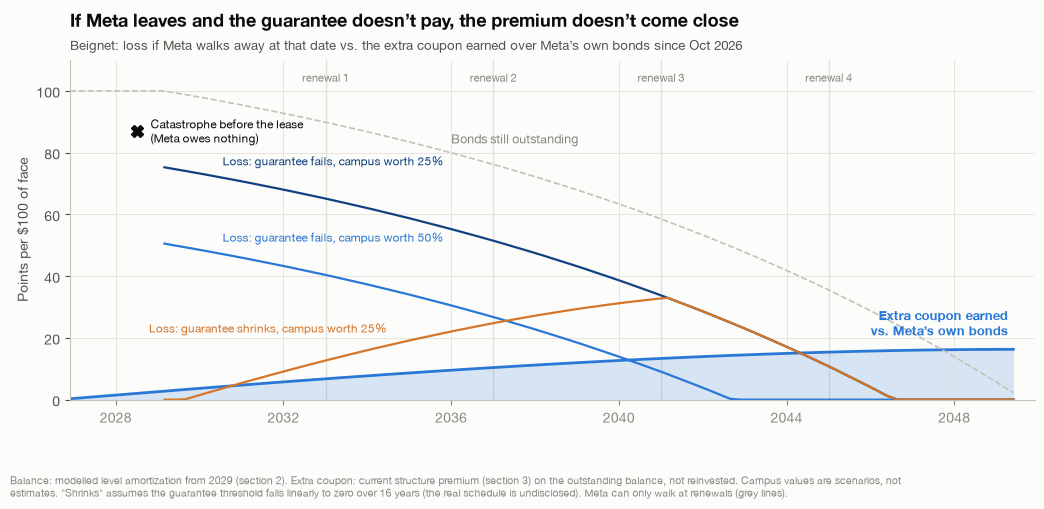

In [12]:
b = 'BEIGNET_6.581_2049'
p = P[b][P[b].index >= AS_OF]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.fill_between(p.index, 0, p['extra coupon earned'], color=BOND, alpha=0.18, lw=0)
ax.plot(p.index, p['extra coupon earned'], color=BOND, lw=2)
ax.plot(p.index, p.balance, color=AXIS, lw=1.2, ls='--')
lines = [('loss: guarantee fails, campus 25%', RAMP[2]), ('loss: guarantee fails, campus 50%', RAMP[1]),
         ('loss: guarantee shrinks, campus 25%', EQUITY)]
for col, c in lines:
    after = p[p.index >= AMORT_START[b]]
    ax.plot(after.index, after[col], color=c, lw=1.6)
start = AMORT_START[b]
for k in range(1, 5):
    d = start + pd.DateOffset(years=4 * k)
    ax.axvline(d, color=GRID, lw=1, zorder=0)
    ax.text(d, 103, f'renewal {k}', ha='center', fontsize=8, color=MUTED)
cat = p.loc[:start - pd.DateOffset(months=6)].iloc[-1]
ax.plot(start - pd.DateOffset(months=6), cat['loss: catastrophe pre-lease'], 'X', ms=9, color=INK)
# direct labels at the right edge
end = p.index[-1]
lab = {'extra coupon earned': ('Extra coupon earned vs. Meta’s bonds', BOND),
       'balance': ('Bonds still outstanding', MUTED)}
ax.annotate(lab['balance'][0], (pd.Timestamp('2036-01-01'), p.balance.asof(pd.Timestamp('2036-01-01'))), xytext=(0, 6),
            textcoords='offset points', fontsize=9, color=MUTED, ha='left')
ax.annotate('Extra coupon earned\nvs. Meta’s own bonds', (end, p['extra coupon earned'].iloc[-1]), xytext=(-4, 8),
            textcoords='offset points', fontsize=9, color=BOND, ha='right', va='bottom', fontweight='bold')
for col, c in lines:
    d = pd.Timestamp({RAMP[2]: '2030-06-01', RAMP[1]: '2030-06-01', EQUITY: '2034-09-01'}[c]); v = p[col].asof(d)
    ax.annotate(col.replace('loss: ', 'Loss: ').replace('campus', 'campus worth'), (d, v), xytext=(-6, 6) if c == EQUITY else (4, 6),
                textcoords='offset points', fontsize=8.5, color=c, ha='right' if c == EQUITY else 'left', va='bottom')
ax.annotate('Catastrophe before the lease\n(Meta owes nothing)', (start - pd.DateOffset(months=6), cat['loss: catastrophe pre-lease']),
            xytext=(10, 0), textcoords='offset points', fontsize=8.5, color=INK, ha='left', va='center')
ax.set_ylim(0, 110); ax.set_xlim(p.index[0], end + pd.DateOffset(months=6))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}'))
ax.set_ylabel('Points per $100 of face')
ax.set_title('If Meta leaves and the guarantee doesn’t pay, the premium doesn’t come close', pad=24)
ax.text(0, 1.03, 'Beignet: loss if Meta walks away at that date vs. the extra coupon earned over Meta’s own bonds since Oct 2026',
        transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'Balance: modelled level amortization from 2029 (section 2). Extra coupon: current structure premium (section 3) on the outstanding balance, not reinvested.\n'
                 'Campus values are scenarios, not estimates. "Shrinks" assumes the guarantee threshold falls linearly to zero over 16 years (the real schedule is undisclosed). Meta can only walk at renewals (grey lines).')
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(CHARTS / '07_spv_vs_meta_scenarios.png', dpi=200)
plt.show()

**What this shows** (`charts/07_spv_vs_meta_scenarios.png`, above):

**The SPV loses while Meta is fine in three specific worlds, and in two of them the premium is nowhere near enough.** Each figure below is points per $100 of face, relative to owning a same-life Meta bond:
- **Meta walks at its first renewal (2033) and the guarantee doesn't reach bondholders.** −30 to −34 if the campus fetches half its cost, ~−58 if a quarter. The extra coupon only catches up with these losses if Meta walks in the 2040s, after most of the principal has been repaid.
- **A catastrophe before the lease starts.** Under the >18-month delay clause, Meta owes neither rent nor guarantee. The insurance (~3% of value) leaves a ~−85 loss. This is the worst case, and the one that most needs confirming from the documents.
- **The guarantee works but has shrunk** (hypothetical straight-line decline). This costs less, −5 to −22, but peaks around renewal 3, when the threshold has fallen faster than the bonds have paid down.

None of these needs Meta to be in any trouble. They need Meta to *decide* to leave a campus it built, which is exactly the option the 4-year lease was designed to give it. **That's what you're paid ~110–125bp for: being short Meta's option to walk.**

**Next:** that's the world where Meta is fine. §6b turns to the world where Meta itself is in trouble.

### 6b · World B: when Meta itself is in trouble, the SPV is the better bond

If Meta files for bankruptcy, its own bondholders are unsecured creditors. They share whatever is left with every other unsecured claim: we assume 40% recovery, as in 03.

The SPV bondholder is in a different position. Meta's bankruptcy forces a choice about each lease:
- **Keep the campus (assume the lease).** If the data center is still useful, Meta has to keep paying rent in full and cure any missed payments. That's the condition for keeping a lease in Chapter 11. The SPV bonds keep being paid while Meta's own bonds are being haircut.
- **Reject the lease.** The bondholder gets the campus, plus an unsecured claim on Meta for the shortfall (the RVG or lease-rejection claim), which recovers at Meta's rate.

$$\text{SPV recovery (lease rejected)} = \text{campus} + R_{\text{Meta}} \times (\text{balance} - \text{campus})$$

As long as the campus is worth anything and the shortfall claim survives, that is always more than $R_{\text{Meta}} \times \text{balance}$. In other words, the SPV holder recovers at least as much as Meta's own bondholders. The catch is that US bankruptcy law caps a landlord's claim for future rent on a rejected lease at roughly 1–3 years of rent (§502(b)(6)). Whether the RVG claim is capped the same way is a question for the documents; we show both.

In [13]:
R_META = bonds.loc['META_5.25_2036', 'assumed_recovery']
rows = []
for b, name in SPV.items():
    bal = P[b].balance.asof(pd.Timestamp('2033-01-01'))          # a Meta default around the first renewal
    cost_per_100 = facts[(b, 'development_cost')] / spv_debt[b] * 100
    one_yr_rent = rent[b] / spv_debt[b] * 100
    for c in CAMPUS:
        campus = c * cost_per_100
        rows.append({'bond': name, 'campus worth': f'{c:.0%} of cost', 'balance (2033)': bal,
                     'Meta’s own bond recovers': R_META * bal,
                     'SPV: Meta keeps the campus': bal,
                     'SPV: lease rejected, full shortfall claim': campus + R_META * max(bal - campus, 0),
                     'SPV: lease rejected, claim capped at 3 yrs rent': campus + R_META * min(max(bal - campus, 0), 3 * one_yr_rent)})
default = pd.DataFrame(rows).set_index(['bond', 'campus worth'])
(default.div(default['balance (2033)'], axis=0) * 100).drop(columns='balance (2033)').round(0).astype(int).astype(str).add('%')

Meta’s own bond recovers SPV: Meta keeps the campus  \
bond       campus worth                                                       
Beignet    50% of cost                       40%                       100%   
           25% of cost                       40%                       100%   
Sopaipilla 50% of cost                       40%                       100%   
           25% of cost                       40%                       100%   

                        SPV: lease rejected, full shortfall claim  \
bond       campus worth                                             
Beignet    50% of cost                                        73%   
           25% of cost                                        56%   
Sopaipilla 50% of cost                                        77%   
           25% of cost                                        59%   

                        SPV: lease rejected, claim capped at 3 yrs rent  
bond       campus worth                                                  
Beignet    50% of cost                                              70%  
           25% of cost                                              42%  
Sopaipilla 50% of cost                                              77%  
           25% of cost                                              48%

**What this shows** (recovery as a share of what's owed, if Meta defaults around 2033):
- Meta's own bonds: 40%.
- The SPV: 100% if Meta keeps the campus; 56–77% if it rejects the lease; 42–77% if the claim is capped at 3 years of rent.
- Even in the worst case, the SPV holder recovers at least as much as Meta's own bondholders.

### 6c · The other reasons a buyer might prefer the SPV

1. **Meta can't dilute you.** Meta's own bonds have nothing to say about what it borrows next. That includes the next Beignet, which takes another campus out from under them. The SPV bondholders own a ring-fenced asset that no future Meta borrowing ranks ahead of. **This is the quiet part:** every SPV Meta does makes Meta's *own* unsecured bonds a little weaker, because a $27B asset now belongs first to someone else. Notebook 05 found the market charges Meta's own bonds almost nothing for this.
2. **Principal comes back early, when Meta's risk is lowest.** Notebook 03 found Meta's implied default risk is back-loaded: ~1% a year in the near term, rising to ~3.6% in the 2040s–50s. An amortizing bond returns most of its principal before then. A Meta bullet of the same *average* life still has all its principal outstanding at maturity.
3. **The premium is a big cushion for a modest set of risks.** World A needs Meta to *choose* to leave a campus it built, *and* the guarantee to fail, or a catastrophe before 2029. In every other world, the SPV holder simply collects ~110–125bp a year more than a Meta bondholder.
4. **What the buyer gives up:** liquidity (a 144A bond with PIMCO holding two-thirds of Beignet), index eligibility, and price transparency. Those are real costs for a mutual fund that has to sell on redemptions. They're nearly costless for an insurer that buys and holds, which is who bought them.

## Findings, by section

**§1 · What you own.** Notes of an issuer tied to an 80/20 JV that owns the campus, not a claim on Meta. You're repaid by Meta's rent, or, if Meta leaves, by the campus plus a residual value guarantee. That guarantee is paid to the JV, conditional on undisclosed "other conditions", and declining.

**§2 · Corrected for amortization, both bonds pay ~250–265bp over Treasuries, not ~205–240.** They are ~15-year bonds, not 22-year ones: weighted average life is 14.7 years for Beignet and 14.5 for Sopaipilla. Our model puts Beignet's issue spread at 232bp, against the press-reported "T+225," a reasonable check on the amortization assumption. The result barely moves if amortization starts a year earlier or later. Straight-line principal would make the spreads *wider*.

**§3 · The structure costs ~110–125bp over Meta's own bonds, and that premium has narrowed since issue.** At issue, Beignet paid ~149bp more than a Meta bond of the same life. Today Beignet pays ~110bp more and Sopaipilla ~124bp more. Over the year, Meta's *own* 15-year spread widened ~58bp (83 → 141bp), while Beignet's widened only ~19bp. **So Beignet's slide is Meta-wide widening plus interest rates, not the market souring on the structure.** Notebook 05 says the same thing from prices: all of Beignet's ~8-point fall is rates.

**§3 · The two deals now price the same.** Sopaipilla came ~40bp wide of where Beignet was trading in July (a new-deal concession on a nervous day), jumped to 103 the next morning, and has since drifted back to its issue spread. Beignet and Sopaipilla are now within ~15bp of each other at the same average life. The market treats them as nearly one structure.

**§4 · The guarantee is sized to the bonds.** Meta's maximum RVG is 1.03× Beignet's bonds and 1.07× Sopaipilla's, and estimated rent covers modelled debt service ~1.26–1.29×. (S&P's 1.12× for Beignet implies either lower net rent or a front-loaded repayment schedule.) On paper, a bondholder is repaid either by Meta's rent or by Meta's guarantee. The premium is the market's price on the gaps in that "either":
- The RVG is paid to the JV, not to the noteholders.
- It pays only if undisclosed "other conditions" are met.
- It declines over time.
- After a catastrophic delay of more than 18 months, Meta may be able to walk away with no guarantee owed, and the campus is insured for a small fraction of its value.

**§4 · For Meta, it's a cheap option, and a big off-balance-sheet number.** Meta pays roughly **$0.5B a year** in extra coupon (at today's premium) for:
- ~$40B of borrowing that isn't on its balance sheet, nearly half again its $84B of reported debt;
- the right to walk away every four years;
- ~$4B of cash taken out at formation.

If Meta renews every time, it's committed to roughly **$92B of rent**, more than its entire reported debt. Its disclosed "maximum exposure" is $68B. The quiet part: the rating agencies say none of this changes Meta's AA-, and the bond market agrees, charging Meta's own bonds nothing for it (05). The cost lands on the SPV bondholders' spread, and they're paid ~110–125bp a year to carry it.

**§5 · If the premium were all default risk, it would be absurd.** At 60% recovery, a ~110–125bp premium implies a ~2.7–3.1% *annual* chance that Meta walks *and* the guarantee fails, about 35% over the bonds' life. Nobody believes that. So most of the premium pays for things other than default:
- **Illiquidity.** These are 144A notes with a handful of holders; PIMCO took ~$18B of Beignet's $27.3B.
- **Index exclusion.** 144A notes without registration rights are left out of the main investment-grade indices, so index money can't buy them. Whether these notes have registration rights is unverified.
- **Complexity and amortization.**
- **Headline risk** attached to the AI capex boom.

For an investor who reads the documents and is comfortable with the gaps, that's the pitch: Meta-adjacent risk at about twice Meta's spread.

**§6 · The SPV loses while Meta is fine in three specific worlds, and in two of them the premium is nowhere near enough.** Each figure below is points per $100 of face, relative to owning a same-life Meta bond:
- **Meta walks at its first renewal (2033) and the guarantee doesn't reach bondholders.** −30 to −34 if the campus fetches half its cost, ~−58 if a quarter. The extra coupon only catches up with these losses if Meta walks in the 2040s, after most of the principal has been repaid.
- **A catastrophe before the lease starts.** Under the >18-month delay clause, Meta owes neither rent nor guarantee. The insurance (~3% of value) leaves a ~−85 loss. This is the worst case, and the one that most needs confirming from the documents.
- **The guarantee works but has shrunk** (hypothetical straight-line decline). This costs less, −5 to −22, but peaks around renewal 3, when the threshold has fallen faster than the bonds have paid down.

None of these needs Meta to be in any trouble. They need Meta to *decide* to leave a campus it built, which is exactly the option the 4-year lease was designed to give it. **That's what you're paid ~110–125bp for: being short Meta's option to walk.**

**§6b–c · In the world where Meta itself is in trouble, the SPV is the better bond.** Meta's own bonds recover an assumed 40%. The SPV bonds recover:
- **100%** if Meta keeps the campus (in bankruptcy it has to keep paying rent in full to keep the lease);
- **56–77%** if Meta rejects the lease, counting the campus plus a claim on Meta for the shortfall;
- **42–77%** if that claim is capped at 3 years of rent.

Other points in the SPV's favour:
- **Meta can't dilute it.** Every new SPV takes another campus out from under Meta's own unsecured bonds, but can't touch this one.
- **Principal comes back early,** before the back-loaded part of Meta's risk curve (03).
- **The holders are buy-and-hold insurers,** for whom illiquidity costs little.

**The pitch in one line:** compared with Meta's own bonds, the SPV is worse if Meta is healthy but walks away, and better if Meta is sick. The market charges ~110–125bp for that trade, which says it thinks a healthy Meta walking away is the more likely of the two. Given that the whole structure exists to give Meta that option, that's probably right.

## Caveats and open items

- **Bankruptcy treatment is assumed, not verified.** Whether the JV is truly separate from Meta in a bankruptcy (true sale, no substantive consolidation), whether Meta would keep or reject the lease, and whether the RVG claim falls under the §502(b)(6) cap on lease claims all depend on the documents and legal opinions, which aren't public.
- **Campus values (50%, 25% of cost) and the straight-line guarantee decline are scenario inputs, not estimates.** The 18-month catastrophe clause is confirmed only for Sopaipilla, from one secondary source; section 6 applies it to Beignet too.

- **Amortization schedules are modelled,** not disclosed. Section 2b shows the range. The offering memoranda or S&P's report would pin them down.
- **Who the RVG pays.** Meta's 10-Q says the RVG was provided "to each of the Ventures." IFR describes it as sized so the bonds get repaid. A newsletter reading of S&P's report says it runs to Project Beignet Holdings, not the issuer, so noteholders are structurally behind it. Both can be true: the JV receives the payment, and the issuer's claim on the JV decides whether it reaches noteholders. **Unresolved.**
- **"Certain other conditions"** for the RVG, and its decline schedule, are not public.
- **Sopaipilla's coupon frequency** is assumed semiannual.
- **Sopaipilla's insurance, and Meta's right to terminate after an 18-month delay,** come from a single secondary source (BigGo, citing the agreement and S&P). They need confirming.
- **Rent is estimated** from Meta's 4-year lease commitments. Louisiana's figure is from Dec 2025; Texas is a residual.